# Navon Global–Local Similarity: Visual Exploration

This notebook explores frozen embeddings from **DINOv2-B** and **SigLIP-B** (`Base`, `UnAligNet`, and `AligNet` exports) on hierarchical Navon letter stimuli (`4,264` images across `A–Z`).

- **Primary representation**: `pre_logits` (768-d), shared across all three variants.
- **Secondary representation**: `triplet_logits` (1024-d) is analyzed separately in the appendix (its projection head is untrained in `Base`).
- **Margin convention**: `margin = cos(reference, global_match) - cos(reference, local_match)` (`> 0` global closer, `< 0` local closer, `0` tie).
- **Important**: Global preference in this similarity task is **not** classification accuracy and **not** evidence of human agreement.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from human_alignment import navon_vis as nv

store = nv.load_workspace()
print(f"Loaded {len(store['items'])} stimuli | {len(store['letters'])} letters | conditions={store['conditions']}")

Loaded 4264 stimuli | 26 letters | conditions=['s10', 's14', 's18']


## 1. What images are we comparing?

Every stimulus is rendered at `224 x 224` RGB upright (`rotation = 0°`) with `DejaVuSans-Bold` and passed through `load_images(..., size=(224, 224))` (`float32` scaled to `[0, 1]`). The gallery below shows the **actual preprocessed inputs** reaching the models:

- **Comparison A (top)**: compound `C(G, L)`, its reversed pair `C(L, G)`, and isolated references `I(G)` / `I(L)` at both `global` (`160 px`) and `local` scale.
- **Comparison B (bottom)**: compound reference `C(G, L)` alongside global-match `C(G, T)` and local-match `C(T, L)` at the same position (`p0`) and shifted position (`p1 = +16 px`).

*Edit `GLOBAL_LETTER`, `LOCAL_LETTER`, `THIRD_LETTER`, or `CONDITION` below to inspect any stimulus set.*

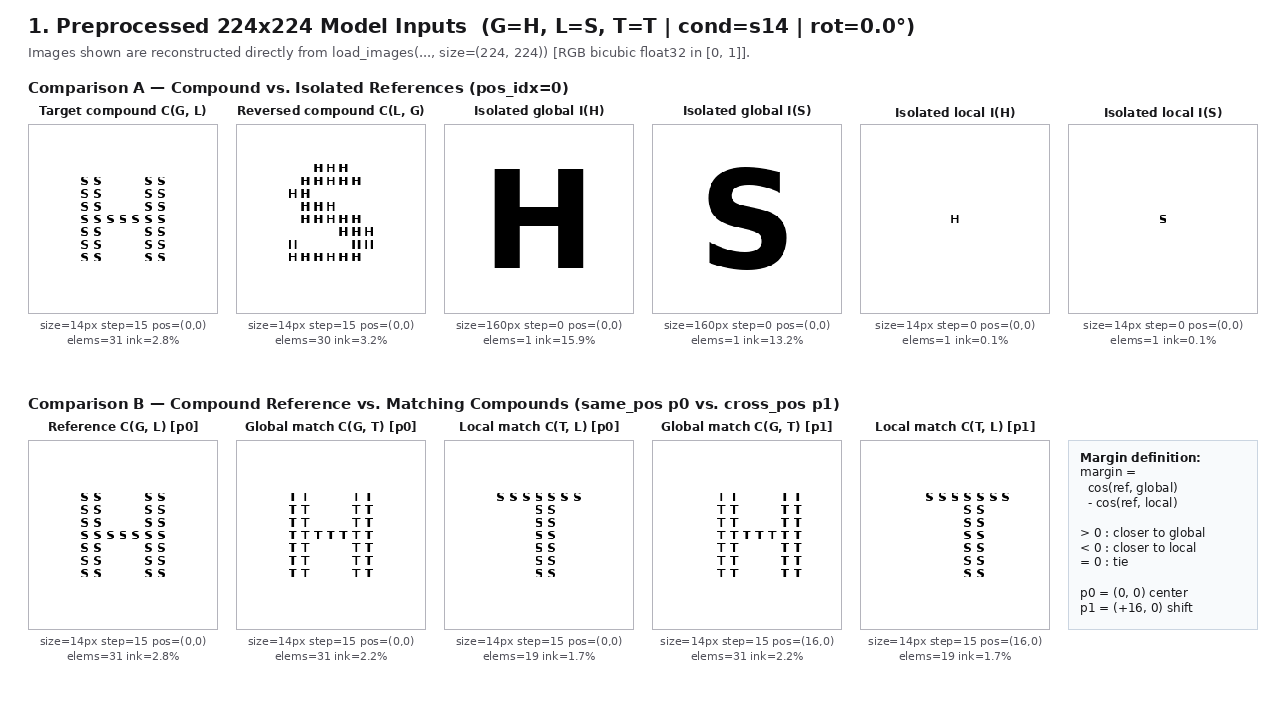

In [1]:
GLOBAL_LETTER = "H"
LOCAL_LETTER = "S"
THIRD_LETTER = "T"
CONDITION = "s14"  # options: "s10", "s14", "s18"
POS_IDX = 0        # options: 0 (center), 1 (+16 px right)

nv.show_stimulus_gallery(GLOBAL_LETTER, LOCAL_LETTER, THIRD_LETTER, CONDITION, POS_IDX)

## 2. How does one example behave?

For a single selected compound `C(G, L)`:

- **Left sub-panels**: raw cosine similarity to the global candidate (filled circle) and local candidate (hollow square) for `Base`, `UnAligNet`, and `AligNet`, on a shared x-axis within each comparison row.
- **Right sub-panels**: the resulting `margin = cos_global - cos_local` relative to the bold `0.00` line (`< 0` favors local match; `> 0` favors global match).

*Switch `RULE` between `"predetermined"`, `"median_margin"`, `"most_global"`, `"most_local"`, or `"largest_alignet_shift"` to inspect score-selected examples (selection rule is always labeled in the figure header).*

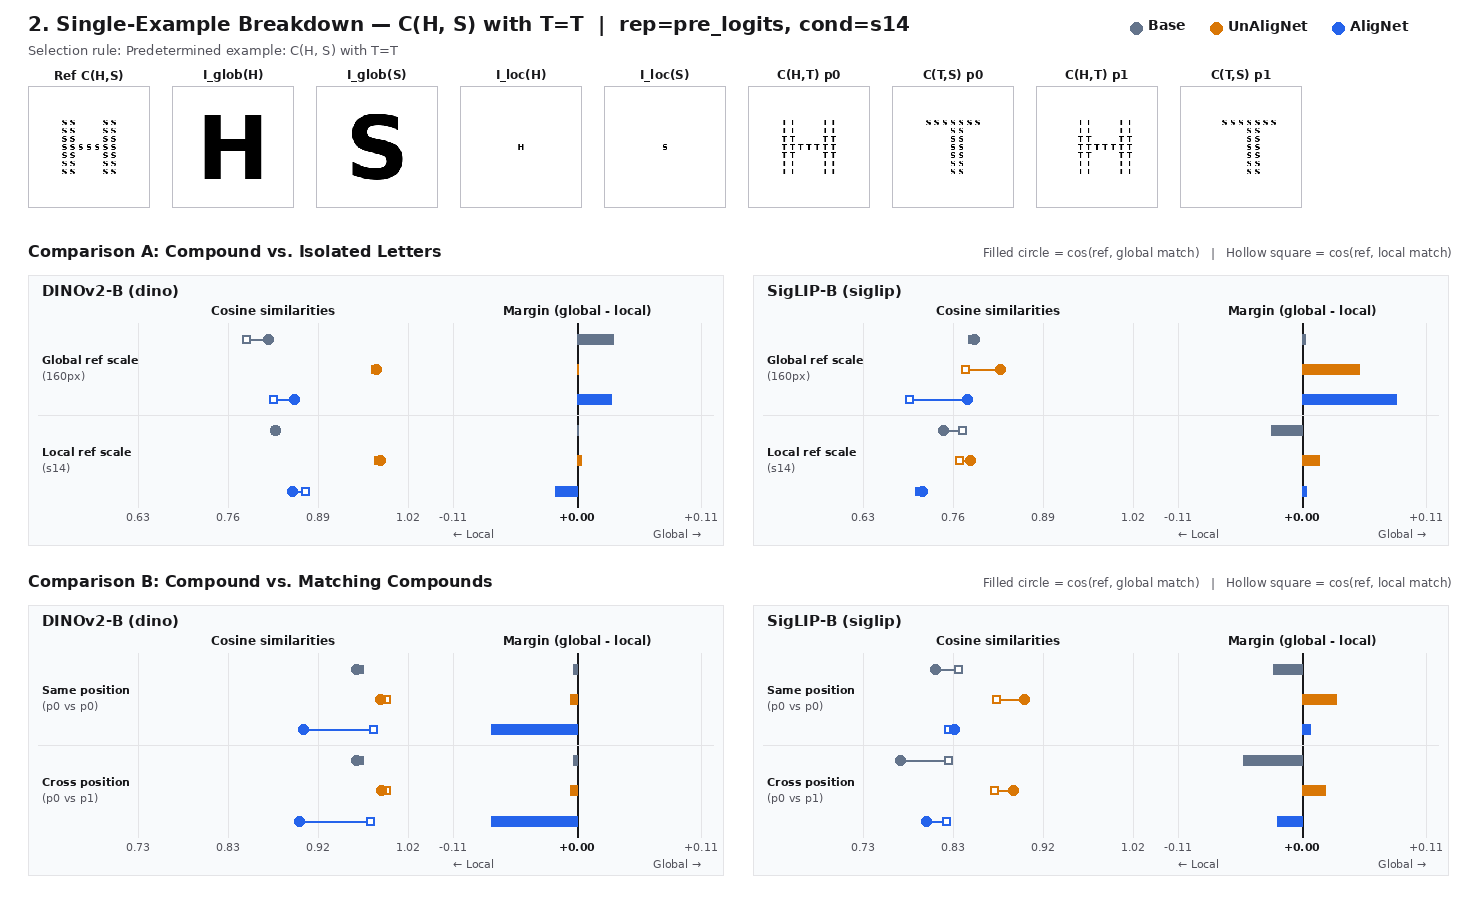

In [2]:
RULE = "predetermined"       # "predetermined", "median_margin", "most_global", "most_local", "largest_alignet_shift"
REPRESENTATION = "pre_logits"
CONDITION = "s14"

g, l, t, rule_label = nv.select_example_by_rule(RULE, representation=REPRESENTATION, family="dino", variant="alignet", condition=CONDITION)
nv.plot_single_example(g, l, t, condition=CONDITION, pos_idx=0, representation=REPRESENTATION, selection_rule=rule_label)

## 3. What happens across the dataset?

- **Left half of each panel (Observations across trials)**: full margin distributions (shaded density + median dot and IQR bar) relative to the vertical `0.00` line, with `Global % (margin > 0)`, `Local % (margin < 0)`, and `Tie % (margin == 0)` printed on the left.
- **Right half of each panel (Paired comparison)**: each point is one of the `325` unordered letter pairs `{G, L}` (averaging `(G, L)` and `(L, G)` to balance glyph-specific ink bias). Horizontal axis = `UnAligNet` margin; vertical axis = `AligNet` margin. Points below the solid diagonal `y = x` indicate a lower (more local / less global) margin in `AligNet` than `UnAligNet`.
- **Uncertainty note**: 95% confidence intervals are computed via cluster bootstrap (`1,000` resamples) over the `325` unordered letter pairs `{G, L}`, keeping repeated positions, conditions, and reversed roles `(G, L)` / `(L, G)` grouped together.

*Edit `COMP_A_SCALE` (`"global"` or `"local"`) or `COMP_B_REGIME` (`"cross_pos"` or `"same_pos"`) to switch views.*

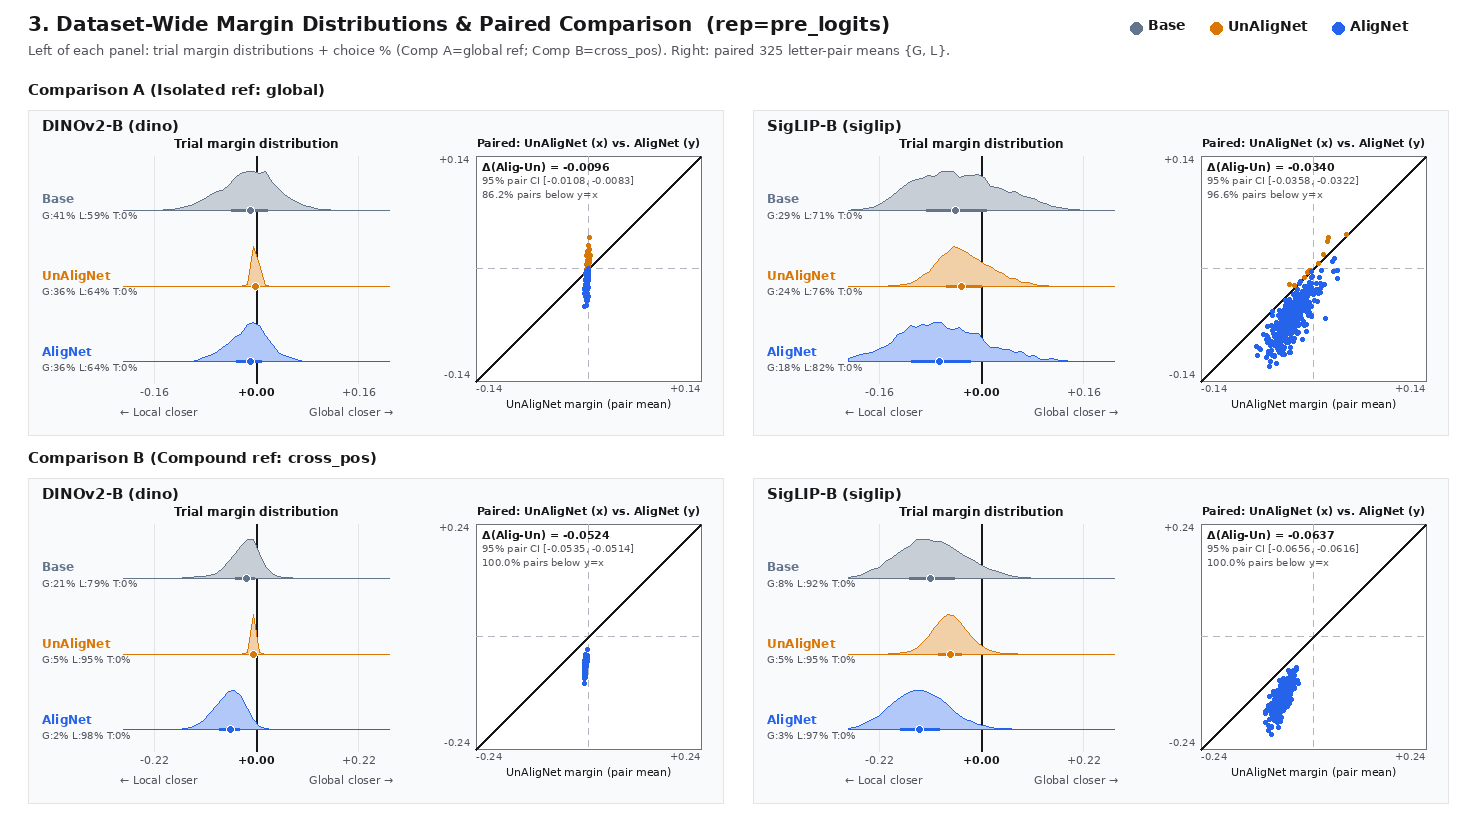

In [3]:
REPRESENTATION = "pre_logits"
COMP_A_SCALE = "global"      # "global" or "local"
COMP_B_REGIME = "cross_pos"  # "cross_pos" or "same_pos"

nv.plot_dataset_overview(REPRESENTATION, comp_a_scale=COMP_A_SCALE, comp_b_regime=COMP_B_REGIME)

## 4. Which conditions or letter combinations matter?

### 4a. Global vs. local letter matrix (`26 × 26`)
Switch `METRIC` between `"alignet_minus_unalignet"`, `"alignet_minus_base"`, `"unalignet_minus_base"`, `"margin_alignet"`, `"margin_unalignet"`, or `"margin_base"`.

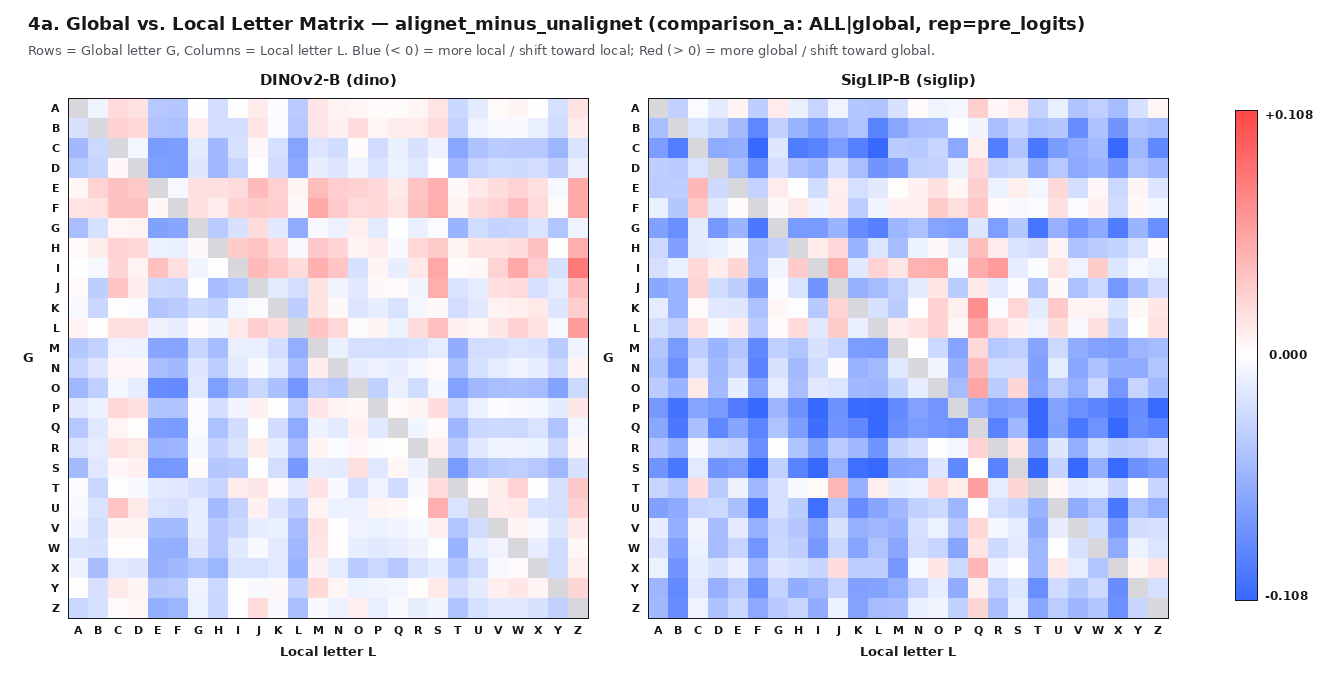

In [4]:
REPRESENTATION = "pre_logits"
COMPARISON = "comparison_a"      # "comparison_a" or "comparison_b"
SUBCONDITION = "ALL|global"      # Comp A: "ALL|global", "ALL|local", "s14|global", ... | Comp B: "ALL|cross_pos", "ALL|same_pos", ...
METRIC = "alignet_minus_unalignet"

nv.plot_letter_heatmap(REPRESENTATION, COMPARISON, SUBCONDITION, METRIC)

### 4b. Rendering conditions present in the dataset
Stimuli vary across three local element size/spacing pairs (`s10 = 10px/11`, `s14 = 14px/15`, `s18 = 18px/19`), two isolated reference scales (`global`, `local`), and two positions (`same_pos`, `cross_pos`). Rotation is fixed at `0°` across all images.

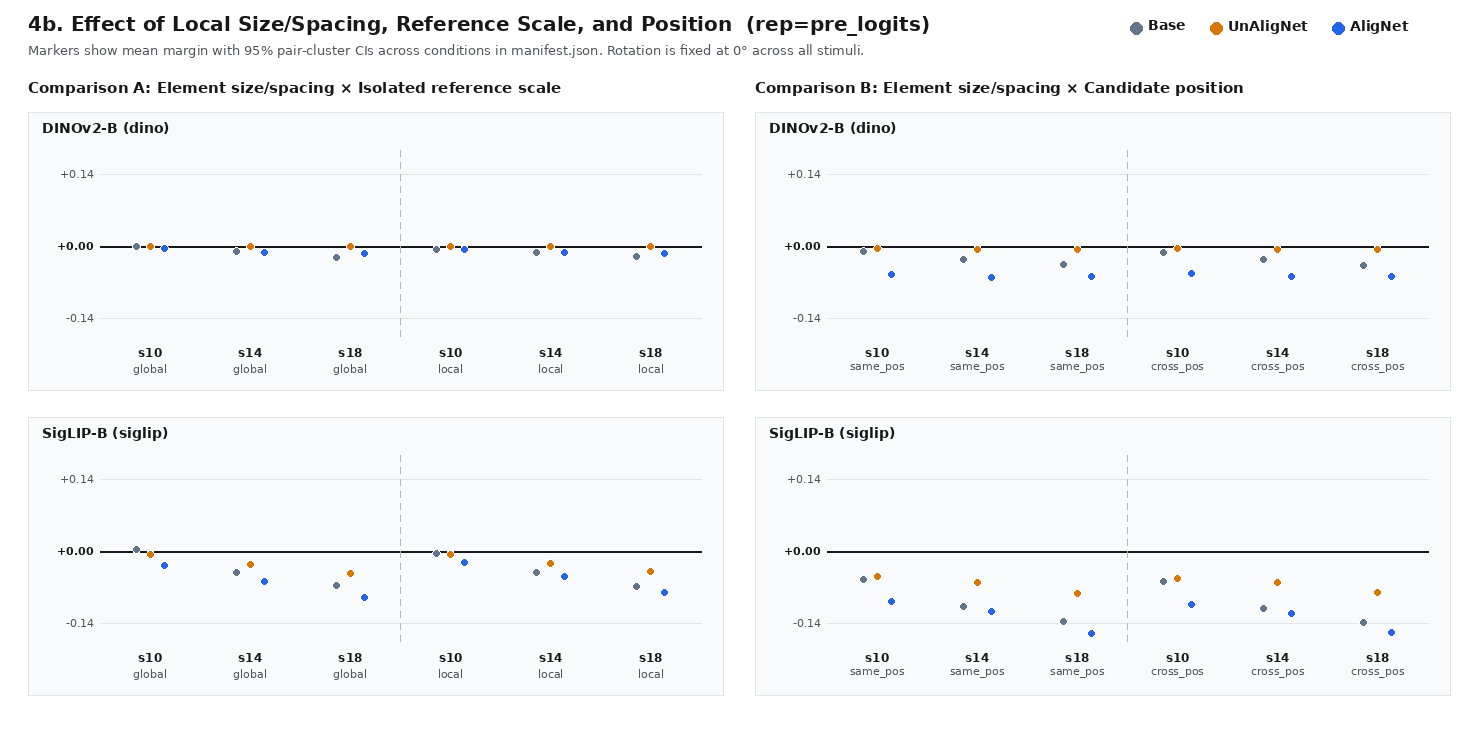

In [5]:
nv.plot_condition_breakdown(representation="pre_logits")

### 4c. Visual inspection of selected cells
Each tile explicitly labels whether it was selected as an extreme value, a median (`typical`) cell, a random sample (`MODE = "random"`), or a manual list (`MODE = "custom"`).

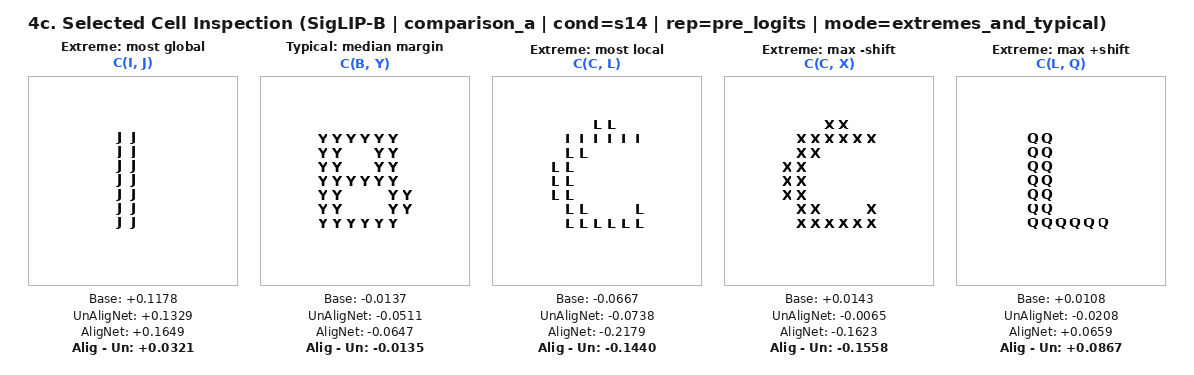

In [6]:
FAMILY = "siglip"                # "dino" or "siglip"
COMPARISON = "comparison_a"      # "comparison_a" or "comparison_b"
CONDITION = "s14"
MODE = "extremes_and_typical"    # "extremes_and_typical", "random", or "custom"
CUSTOM_PAIRS = [("H", "S"), ("O", "I"), ("E", "F")]

nv.show_cell_gallery("pre_logits", FAMILY, COMPARISON, CONDITION, MODE, custom_pairs=CUSTOM_PAIRS, seed=0)

## 5. Check the letter-substitution issue

In Comparison B (`cos(C(G, L), C(G, T)) - cos(C(G, L), C(T, L))`), the score for any triad `(G, L, T)` can shift depending on whether replacement letter `T` happens to resemble `G` or `L`.

To test global vs. local sensitivity without relying on a single `T` triad:
1. **Top diagram**: shows the exact same letter replacement `H ↔ S` applied globally (`C(H, T)` vs. `C(S, T)`) and locally (`C(T, H)` vs. `C(T, S)`), all rendered at identical `pos_idx = 0` (`(0, 0)`) and `rotation = 0°`.
2. **Bottom left**: plots single-triad `compound_margin(G, L, T)` against `T`'s isolated-letter resemblance asymmetry `cos(I(T), I(L)) - cos(I(T), I(G))`.
3. **Bottom right**: averages over all `24` unchanged letters `Z ≠ X, Y` across all `325` pairs `{X, Y}` to compare similarity when global `Z` is preserved (`local X ↔ Y` swapped) minus similarity when local `Z` is preserved (`global X ↔ Y` swapped).

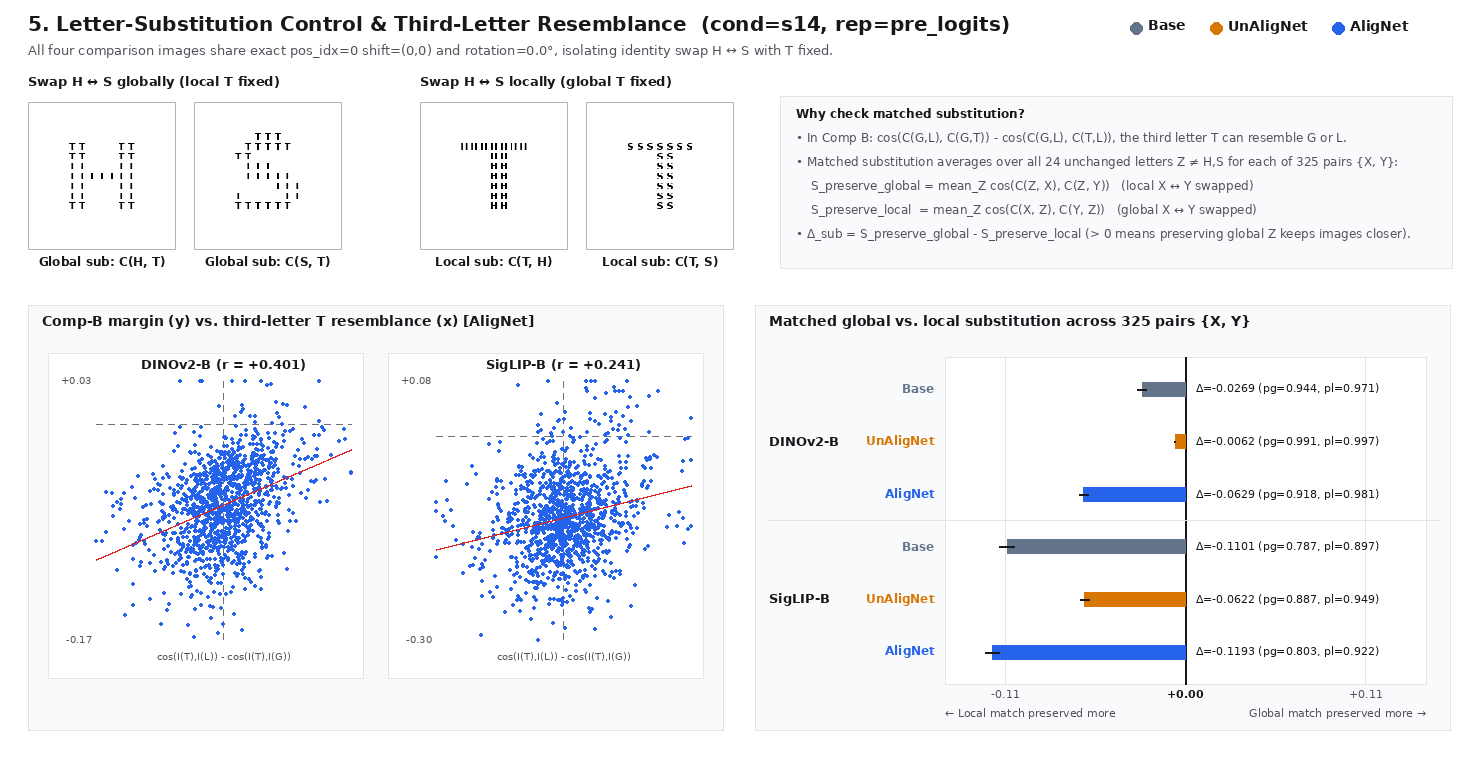

In [7]:
nv.plot_substitution_check(representation="pre_logits", condition="s14", pos_idx=0, example_x="H", example_y="S", example_z="T")

## 6. Observations and open questions

### Observations (from `pre_logits` outputs)
- **Baseline direction**: Across all six checkpoints and both comparison designs, mean margins are negative (`local` match closer than `global` match). In Comparison B (`cross_pos`), `UnAligNet` and `AligNet` favor the local match on over `95%` of triads in both `DINOv2-B` and `SigLIP-B`.
- **AligNet vs. UnAligNet contrast**: In both `DINOv2-B` and `SigLIP-B`, paired `AligNet - UnAligNet` margin differences are negative across every aggregate comparison slice (`95%` pair-cluster bootstrap CIs exclude zero). By contrast, ordinary distillation (`UnAligNet - Base`) shifts margins slightly less negative relative to `Base` while lowering raw `global_frac` in several slices.
- **Scale & position**: Local preference strengthens monotonically as local elements grow larger and sparser (`s10 → s14 → s18`). In Comparison B, `same_pos` and `cross_pos` (`+16 px` shift) behave nearly identically, suggesting the local preference is not driven purely by exact canvas pixel overlap.
- **Letter-substitution control**: Even when swapping identical letters `X ↔ Y` at matched position and `0°` rotation and averaging over all `24` unchanged letters `Z`, preserving the local letter yields higher cosine similarity than preserving the global letter (`Δ_sub < 0`) in all variants, with `AligNet` again showing a more negative `Δ_sub` than `UnAligNet`.

### Open questions
- **Why does `AligNet` increase local preference on synthetic letters?** Does aligning representations to natural-object conceptual similarity (THINGS/ImageNet triplets) attenuate sensitivity to sparse, silhouette-defined global letter arrangements, or rely more on high-frequency local stroke features?
- **DINOv2-B preprocessing provenance**: Both families use `[0, 1]` bicubic RGB scaling because public AligNet docs do not specify a separate DINO inference preprocessing transform. Would ImageNet mean/std normalization alter DINOv2-B's baseline margin or the `AligNet - UnAligNet` contrast?
- **Similarity vs. task readout / human baseline**: Direct cosine similarity on frozen `pre_logits` measures unguided representational similarity rather than a global/local identification task, and we do not have human judgments on these exact stimuli. Testing a Cue-Conflict or Silhouettes benchmark with recorded human choices is a natural next step.

## Appendix (Optional): Secondary representation (`triplet_logits`) & full tables

`triplet_logits` (`1024`-d) is the alignment projection head (trained in `UnAligNet` and `AligNet`, untrained in `Base`). Set `SHOW_TRIPLET_PLOT = True` or `SHOW_DETAILED_TABLES = True` to inspect them.

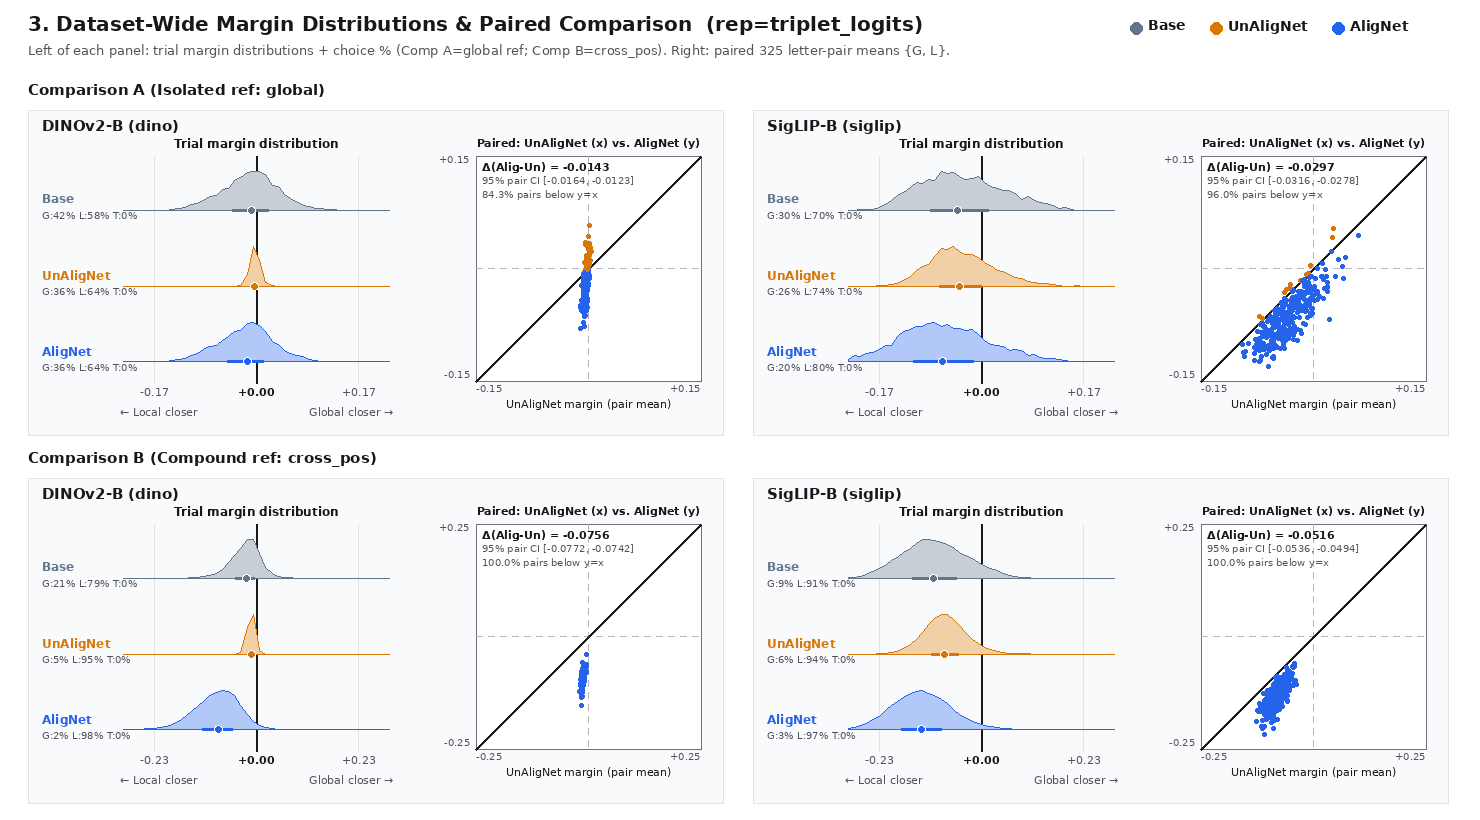

In [8]:
SHOW_TRIPLET_PLOT = True
SHOW_DETAILED_TABLES = False

if SHOW_TRIPLET_PLOT:
    img = nv.plot_dataset_overview("triplet_logits", comp_a_scale="global", comp_b_regime="cross_pos")
else:
    img = None

if SHOW_DETAILED_TABLES:
    nv.print_summary_tables("pre_logits")

img